In [41]:
#
# Reference Link: https://ataspinar.com/posts/the-perceptron/
#

import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

class Perceptron():
    """
    Class for performing Perceptron.
    X is the input array with n rows (no_examples) and m columns (no_features)
    Y is a vector containing elements which indicate the class
        (1 for positive class, -1 for negative class)
    w is the weight-vector (m number of elements)
    b is the bias-value
    """
    def __init__(self, b = 0, max_iter = 1000):
        self.max_iter = max_iter
        self.w = []
        self.b = 0
        self.no_examples = 0
        self.no_features = 0

    def train(self, X, Y):
        self.no_examples, self.no_features = np.shape(X)
        self.w = np.zeros(self.no_features)
        for ii in range(0, self.max_iter):
            w_updated = False
            for jj in range(0, self.no_examples):
                a = self.b + np.dot(self.w, X[jj])
                if np.sign(Y[jj]*a) != 1:
                    w_updated = True
                    self.w += Y[jj] * X[jj]
                    self.b += Y[jj]
            if not w_updated:
                print("Convergence reached in %i iterations." % ii)
                break
        if w_updated:
            print(
            """
            WARNING: convergence not reached in %i iterations.
            Either dataset is not linearly separable,
            or max_iter should be increased
            """ % self.max_iter
                )

    def classify_element(self, x_elem):
        return int(np.sign(self.b + np.dot(self.w, x_elem)))

    def classify(self, X):
        predicted_Y = []
        for ii in range(np.shape(X)[0]):
            y_elem = self.classify_element(X[ii])
            predicted_Y.append(y_elem)
        return predicted_Y

In [42]:
# Generate data
def generate_data(no_points):
    X = np.zeros(shape=(no_points, 2))
    Y = np.zeros(shape=no_points)
    for ii in range(no_points):
        X[ii][0] = random.randint(1,9)+0.5
        X[ii][1] = random.randint(1,9)+0.5
        Y[ii] = 1 if X[ii][0]+X[ii][1] >= 13 else -1
    return X, Y


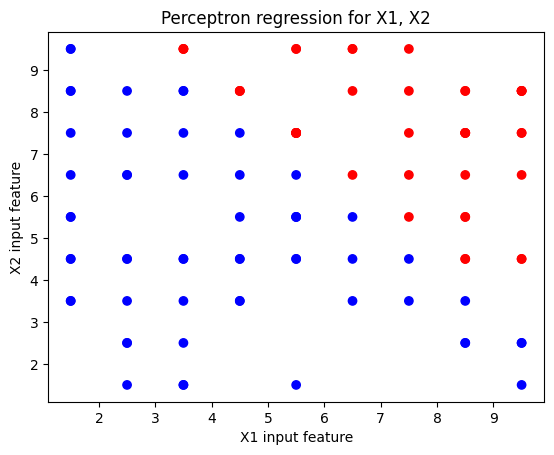

In [49]:
#In the 2D case, the perceptron algorithm looks like:
X, Y = generate_data(100)

x1 = X[:, 0]
x2 = X[:, 1]
color = ['red' if value == 1 else 'blue' for value in Y]
plt.scatter(x1, x2, marker='o', color=color)
plt.xlabel('X1 input feature')
plt.ylabel('X2 input feature')
plt.title('Perceptron regression for X1, X2')
plt.show()
